In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/robinaz/equities/equities.csv


# Step 1: Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Step 2: Load the data

In [3]:
data = pd.read_csv('/kaggle/input/datasets/robinaz/sector/sector_prices.csv')
data['Date'] = pd.to_datetime(data['Date'])
data.head()

,Date,Sector,Price
0,2021-01-04,Energy,253.777267
1,2021-01-05,Energy,271.726074
2,2021-01-06,Energy,288.976807
3,2021-01-07,Energy,294.162231
4,2021-01-08,Energy,297.851715


# Step 3: Calculate daily returns (%) for each sector

In [4]:
data = data.sort_values(['Sector', 'Date'])
data['Return'] = data.groupby('Sector')['Price'].pct_change() * 100
data = data.dropna()
data.head()

,Date,Sector,Price,Return
1260,2021-01-05,Banks,377.339294,-0.460102
1261,2021-01-06,Banks,414.764374,9.918151
1262,2021-01-07,Banks,415.661316,0.216253
1263,2021-01-08,Banks,410.378845,-1.270859
1264,2021-01-11,Banks,406.840790,-0.862144


groupby('Sector') makes sure each return is calculated within its own sector, so the last Banks price is never compared with the first Energy price.

# Step 4: Group means

In [6]:
data.groupby('Sector')['Return'].agg(['count', 'mean', 'std'])

,count,mean,std
Sector,,,
Banks,1258,0.102149,1.557977
Energy,1258,0.058459,1.807661
Retail,1258,0.040819,1.355533


# Step 5: Visualise the three groups

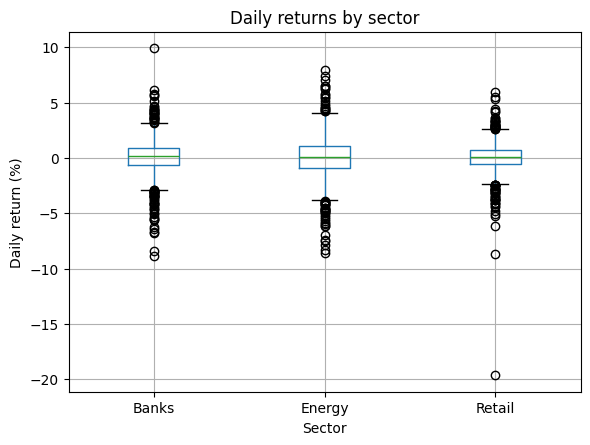

In [7]:
data.boxplot(column='Return', by='Sector')
plt.ylabel('Daily return (%)')
plt.title('Daily returns by sector')
plt.suptitle('')
plt.show()

# Step 6: Hypotheses

H0: μEnergy = μBanks = μRetail (all sectors have the same mean return)
H1: not all the means are equal
α = 0.05

In [8]:
energy = data[data['Sector'] == 'Energy']['Return']
banks  = data[data['Sector'] == 'Banks']['Return']
retail = data[data['Sector'] == 'Retail']['Return']

F, p = stats.f_oneway(energy, banks, retail)
print('F statistic:', round(F, 3))
print('p-value:', round(p, 4))

F statistic: 0.499
p-value: 0.6069


# Step 8: Make a decision

In [9]:
alpha = 0.05
if p < alpha:
    print('Reject H0: at least one sector has a different mean return')
else:
    print('Do not reject H0: no evidence that mean returns differ across sectors')

Do not reject H0: no evidence that mean returns differ across sectors


# Step 9: The ANOVA table (same format as the lecture)

In [10]:
c = data['Sector'].nunique()
nT = len(data)
grand_mean = data['Return'].mean()
group = data.groupby('Sector')['Return']

SSTR = (group.count() * (group.mean() - grand_mean)**2).sum()
SSE  = ((data['Return'] - group.transform('mean'))**2).sum()
df1, df2 = c - 1, nT - c
MSTR, MSE = SSTR / df1, SSE / df2
F_stat = MSTR / MSE
p_value = stats.f.sf(F_stat, df1, df2)

table = pd.DataFrame({
    'SS': [SSTR, SSE, SSTR + SSE],
    'df': [df1, df2, nT - 1],
    'MS': [MSTR, MSE, None],
    'F':  [F_stat, None, None],
    'p-value': [p_value, None, None]},
    index=['Between groups (Sector)', 'Within groups (Error)', 'Total'])
print(table.round(4).fillna(''))
print('Critical F (5%):', round(stats.f.ppf(0.95, df1, df2), 3))

                                SS    df      MS       F p-value
Between groups (Sector)     2.5082     2  1.2541  0.4995  0.6069
Within groups (Error)    9468.2286  3771  2.5108                
Total                    9470.7368  3773                        
Critical F (5%): 2.998


# Interpretation

A one-way ANOVA was used to test whether average daily returns differ across the Energy (BP), Banks (HSBC) and Retail (Tesco) sectors from 2021 to 2025.

H0: all three sectors have the same mean daily return. H1: not all the means are equal.
Result: F(2, 3771) = 0.50, p = 0.607.
Decision: F = 0.50 is less than the critical value of 2.998, and p = 0.607 > 0.05, so we do not reject H0.

Conclusion: At the 5% significance level, there is no significant difference in average daily returns across the three sectors. Banks had the highest mean (0.10%) and Retail the lowest (0.04%), but these differences are small compared with the day-to-day variation in returns, so they can be explained by chance.